In [2]:
# ============================================================
# 1. MOUNT GOOGLE DRIVE AND INSTALL DEPENDENCIES
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

!pip -q install transformers accelerate scikit-learn pandas pillow tqdm matplotlib

Mounted at /content/drive


In [3]:
# ============================================================
# 2. IMPORT LIBRARIES AND CONFIGURATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from torch.utils.data import Dataset, DataLoader

from transformers import (
    CLIPProcessor,
    CLIPModel
)

from sklearn.model_selection import (
    GroupShuffleSplit,
    train_test_split
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

# ------------------------------------------------------------
# GOOGLE DRIVE PATHS
# ------------------------------------------------------------

PROJECT_DIR = (
    "/content/drive/MyDrive/EEE6778_Semester_Project"
)

DATASET_PATH = os.path.join(
    PROJECT_DIR,
    "BLIP_generated_dataset.csv"
)

MODEL_OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "clip_contrastive_model"
)

os.makedirs(
    MODEL_OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# CLIP CONFIGURATION
# ------------------------------------------------------------

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

BATCH_SIZE = 32

EPOCHS = 8

LEARNING_RATE = 5e-6

WEIGHT_DECAY = 0.05

VALIDATION_SIZE = 0.20

print("Dataset:", DATASET_PATH)
print("Model output:", MODEL_OUTPUT_DIR)

Device: cuda
Dataset: /content/drive/MyDrive/EEE6778_Semester_Project/BLIP_generated_dataset.csv
Model output: /content/drive/MyDrive/EEE6778_Semester_Project/clip_contrastive_model


In [4]:
# ============================================================
# 3. LOAD BLIP GENERATED DATASET
# ============================================================

if not os.path.isfile(DATASET_PATH):

    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH)

required_columns = [
    "image_path",
    "alt_text",
    "label"
]

for col in required_columns:

    if col not in df.columns:

        raise ValueError(
            f"Missing required column: {col}"
        )

# Convert labels to integers.
df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

df = df.dropna(
    subset=["image_path", "alt_text", "label"]
).copy()

df["label"] = df["label"].astype(int)

# Keep only valid binary labels.
df = df[df["label"].isin([0, 1])]

# Remove empty captions.
df["alt_text"] = df["alt_text"].astype(str).str.strip()

df = df[df["alt_text"] != ""]

# Remove rows whose images no longer exist.
df = df[
    df["image_path"].apply(os.path.isfile)
].copy()

df = df.reset_index(drop=True)

print("Total dataset rows:", len(df))

print("\nLabel distribution:")

print(df["label"].value_counts())

print("\nDataset columns:")

print(df.columns.tolist())

display(df.head())

Total dataset rows: 2002

Label distribution:
label
1    1001
0    1001
Name: count, dtype: int64

Dataset columns:
['document_id', 'page_id', 'figure_id', 'image_path', 'alt_text', 'label', 'pair_type', 'caption_source_image_path', 'caption_source_image_id']


,document_id,page_id,figure_id,image_path,alt_text,label,pair_type,caption_source_image_path,caption_source_image_id
0,images,NaN,doc_514_figure_0,/content/drive/MyDrive/EEE6778_Semester_Projec...,an aerial view of a bridge over a body of water,1,positive,/content/drive/MyDrive/EEE6778_Semester_Projec...,697
1,images,NaN,doc_1221_figure_8,/content/drive/MyDrive/EEE6778_Semester_Projec...,a black and white photo of a smiling man,0,negative,/content/drive/MyDrive/EEE6778_Semester_Projec...,485
2,images,NaN,doc_459_figure_6,/content/drive/MyDrive/EEE6778_Semester_Projec...,the signature of a man in blue ink on a white ...,1,positive,/content/drive/MyDrive/EEE6778_Semester_Projec...,667
3,images,NaN,doc_1695_figure_0,/content/drive/MyDrive/EEE6778_Semester_Projec...,"a table with two columns, one column and one c...",1,positive,/content/drive/MyDrive/EEE6778_Semester_Projec...,453
4,images,NaN,doc_420_figure_1,/content/drive/MyDrive/EEE6778_Semester_Projec...,a pie pie pie pie pie pie pie pie pie pie pie ...,1,positive,/content/drive/MyDrive/EEE6778_Semester_Projec...,645


In [5]:
# ============================================================
# 4. PREPARE POSITIVE AND NEGATIVE PAIRS
# ============================================================

positive_df = df[
    df["label"] == 1
].copy()

negative_df = df[
    df["label"] == 0
].copy()

# Keep one positive caption per image.
positive_df = positive_df.drop_duplicates(
    subset=["image_path"],
    keep="first"
).reset_index(drop=True)

# Ensure that the positive dataset has unique images.
print("Unique positive images:", len(positive_df))

print("Negative pairs available:", len(negative_df))

# Check that we have enough unique images.
if len(positive_df) < 3:

    raise ValueError(
        "At least three unique positive image-caption pairs "
        "are needed for training and validation."
    )

# ------------------------------------------------------------
# CHECK DOCUMENT GROUPS
# ------------------------------------------------------------

if "document_id" in positive_df.columns:

    positive_df["document_id"] = (
        positive_df["document_id"].fillna("UNKNOWN")
    )

    num_documents = positive_df["document_id"].nunique()

else:

    num_documents = 0

print("Unique document groups:", num_documents)

Unique positive images: 1001
Negative pairs available: 1001
Unique document groups: 1


In [6]:
# ============================================================
# 5. TRAIN / VALIDATION SPLIT
# ============================================================

if (
    "document_id" in positive_df.columns
    and positive_df["document_id"].nunique() >= 2
):

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_SIZE,
        random_state=SEED
    )

    train_idx, val_idx = next(
        splitter.split(
            positive_df,
            groups=positive_df["document_id"]
        )
    )

    print("Using document-level splitting.")

else:

    print(
        "WARNING: Fewer than two document groups found. "
        "Using image-level splitting instead."
    )

    train_idx, val_idx = train_test_split(
        np.arange(len(positive_df)),
        test_size=VALIDATION_SIZE,
        random_state=SEED
    )


train_df = positive_df.iloc[
    train_idx
].reset_index(drop=True)

val_df = positive_df.iloc[
    val_idx
].reset_index(drop=True)


print("\nTraining images:", len(train_df))

print("Validation images:", len(val_df))

print(
    "Training documents:",
    train_df["document_id"].nunique()
    if "document_id" in train_df.columns else "N/A"
)

print(
    "Validation documents:",
    val_df["document_id"].nunique()
    if "document_id" in val_df.columns else "N/A"
)

# Check image separation.
assert set(train_df["image_path"]).isdisjoint(
    set(val_df["image_path"])
)


Training images: 800
Validation images: 201
Training documents: 1
Validation documents: 1


In [7]:
# ============================================================
# 6. CREATE TRAINING AND VALIDATION NEGATIVE MAPPINGS
# ============================================================

def build_negative_mapping(
    split_df,
    all_negative_df
):

    split_image_paths = set(
        split_df["image_path"]
    )

    mapping = {}

    for _, row in split_df.iterrows():

        target_path = row["image_path"]

        candidates = all_negative_df[
            all_negative_df["image_path"] == target_path
        ]

        # Only use negative captions whose source images
        # belong to this same split.
        if "caption_source_image_path" in candidates.columns:

            candidates = candidates[
                candidates["caption_source_image_path"].isin(
                    split_image_paths
                )
            ]

        if len(candidates) > 0:

            mapping[target_path] = (
                candidates.iloc[0]["alt_text"]
            )

        else:

            # Fallback: use another image's positive caption.
            alternative_captions = split_df[
                split_df["image_path"] != target_path
            ]

            if len(alternative_captions) > 0:

                mapping[target_path] = (
                    alternative_captions.iloc[0]["alt_text"]
                )

    return mapping


train_negative_mapping = build_negative_mapping(
    train_df,
    negative_df
)

val_negative_mapping = build_negative_mapping(
    val_df,
    negative_df
)


print(
    "Training hard negatives:",
    len(train_negative_mapping)
)

print(
    "Validation hard negatives:",
    len(val_negative_mapping)
)

# Every image should have a mismatched caption.
assert len(train_negative_mapping) == len(train_df)

assert len(val_negative_mapping) == len(val_df)

Training hard negatives: 800
Validation hard negatives: 201


In [8]:
# ============================================================
# 7. LOAD PRETRAINED CLIP MODEL
# ============================================================

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL_NAME
)

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_NAME
).to(DEVICE)

print("CLIP model loaded successfully.")

print("Model:", CLIP_MODEL_NAME)

print("Device:", DEVICE)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP model loaded successfully.
Model: openai/clip-vit-base-patch32
Device: cuda


In [9]:
# ============================================================
# 8. CREATE PYTORCH DATASET
# ============================================================

class BLIPContrastiveDataset(Dataset):

    def __init__(
        self,
        dataframe,
        negative_mapping
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.negative_mapping = negative_mapping

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]

        positive_caption = row["alt_text"]

        negative_caption = self.negative_mapping[
            image_path
        ]

        # Load image.
        with Image.open(image_path) as image:

            image = image.convert("RGB")

        return {

            "image": image,

            "positive_caption": positive_caption,

            "negative_caption": negative_caption

        }


# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------

def contrastive_collate_fn(batch):

    images = [
        item["image"]
        for item in batch
    ]

    positive_captions = [
        item["positive_caption"]
        for item in batch
    ]

    negative_captions = [
        item["negative_caption"]
        for item in batch
    ]

    return {

        "images": images,

        "positive_captions": positive_captions,

        "negative_captions": negative_captions

    }


# ------------------------------------------------------------
# CREATE DATASETS
# ------------------------------------------------------------

train_dataset = BLIPContrastiveDataset(
    train_df,
    train_negative_mapping
)

val_dataset = BLIPContrastiveDataset(
    val_df,
    val_negative_mapping
)


# ------------------------------------------------------------
# CREATE DATALOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=contrastive_collate_fn,
    num_workers=0,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=contrastive_collate_fn,
    num_workers=0,
    drop_last=False
)


print("Training batches:", len(train_loader))

print("Validation batches:", len(val_loader))

Training batches: 25
Validation batches: 7


In [10]:
# ============================================================
# 9. DEFINE CONTRASTIVE LOSS
# ============================================================

def extract_embeddings(model_output):
    """
    Extract embeddings from Hugging Face CLIP outputs.

    Supports:
    - Tensor outputs
    - BaseModelOutputWithPooling objects
    """

    if isinstance(model_output, torch.Tensor):

        embeddings = model_output

    elif hasattr(model_output, "pooler_output"):

        embeddings = model_output.pooler_output

    elif hasattr(model_output, "last_hidden_state"):

        # Use the first token as a fallback.
        embeddings = model_output.last_hidden_state[:, 0, :]

    else:

        raise TypeError(
            f"Unsupported model output type: {type(model_output)}"
        )

    return embeddings


def calculate_contrastive_loss(
    model,
    batch,
    return_details=False
):

    images = batch["images"]

    positive_captions = batch["positive_captions"]

    negative_captions = batch["negative_captions"]


    # ========================================================
    # PROCESS IMAGES AND POSITIVE CAPTIONS
    # ========================================================

    positive_inputs = clip_processor(
        images=images,
        text=positive_captions,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    positive_inputs = {
        key: value.to(DEVICE)
        for key, value in positive_inputs.items()
    }


    # ========================================================
    # PROCESS NEGATIVE CAPTIONS
    # ========================================================

    negative_inputs = clip_processor(
        text=negative_captions,
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    negative_inputs = {
        key: value.to(DEVICE)
        for key, value in negative_inputs.items()
    }


    # ========================================================
    # EXTRACT IMAGE EMBEDDINGS
    # ========================================================

    image_output = model.get_image_features(
        pixel_values=positive_inputs["pixel_values"]
    )

    image_embeddings = extract_embeddings(
        image_output
    )


    # ========================================================
    # EXTRACT POSITIVE TEXT EMBEDDINGS
    # ========================================================

    positive_output = model.get_text_features(
        input_ids=positive_inputs["input_ids"],
        attention_mask=positive_inputs["attention_mask"]
    )

    positive_embeddings = extract_embeddings(
        positive_output
    )


    # ========================================================
    # EXTRACT NEGATIVE TEXT EMBEDDINGS
    # ========================================================

    negative_output = model.get_text_features(
        input_ids=negative_inputs["input_ids"],
        attention_mask=negative_inputs["attention_mask"]
    )

    negative_embeddings = extract_embeddings(
        negative_output
    )


    # ========================================================
    # NORMALIZE EMBEDDINGS
    # ========================================================

    image_embeddings = F.normalize(
        image_embeddings,
        p=2,
        dim=-1
    )

    positive_embeddings = F.normalize(
        positive_embeddings,
        p=2,
        dim=-1
    )

    negative_embeddings = F.normalize(
        negative_embeddings,
        p=2,
        dim=-1
    )


    # ========================================================
    # CLIP TEMPERATURE
    # ========================================================

    logit_scale = model.logit_scale.exp()


    # ========================================================
    # IMAGE-TO-TEXT CONTRASTIVE LOSS
    # ========================================================

    all_text_embeddings = torch.cat(
        [
            positive_embeddings,
            negative_embeddings
        ],
        dim=0
    )

    logits_image_to_text = (
        logit_scale
        * image_embeddings
        @ all_text_embeddings.T
    )

    batch_size = image_embeddings.shape[0]

    targets = torch.arange(
        batch_size,
        device=DEVICE
    )

    loss_image_to_text = F.cross_entropy(
        logits_image_to_text,
        targets
    )


    # ========================================================
    # TEXT-TO-IMAGE CONTRASTIVE LOSS
    # ========================================================

    logits_text_to_image = (
        logit_scale
        * positive_embeddings
        @ image_embeddings.T
    )

    loss_text_to_image = F.cross_entropy(
        logits_text_to_image,
        targets
    )


    # ========================================================
    # COMBINE LOSSES
    # ========================================================

    loss = (
        loss_image_to_text
        + loss_text_to_image
    ) / 2


    if return_details:

        return {

            "loss": loss,

            "image_to_text_loss": loss_image_to_text,

            "text_to_image_loss": loss_text_to_image,

            "image_embeddings": image_embeddings,

            "positive_embeddings": positive_embeddings,

            "negative_embeddings": negative_embeddings

        }

    return loss


print("Updated contrastive loss function loaded.")

Updated contrastive loss function loaded.


In [11]:
# ============================================================
# 10. INITIALIZE TRAINING
# ============================================================

# Require at least two training examples per batch.
if len(train_dataset) < 2:
    raise ValueError(
        "At least two training images are required."
    )

# Adjust batch size if the dataset is smaller than expected.
EFFECTIVE_BATCH_SIZE = min(
    BATCH_SIZE,
    len(train_dataset)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=EFFECTIVE_BATCH_SIZE,
    shuffle=True,
    collate_fn=contrastive_collate_fn,
    num_workers=0,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EFFECTIVE_BATCH_SIZE,
    shuffle=False,
    collate_fn=contrastive_collate_fn,
    num_workers=0,
    drop_last=False
)

optimizer = torch.optim.AdamW(
    clip_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

best_val_loss = float("inf")

PATIENCE = 2

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "learning_rate": []
}

print("Effective batch size:", EFFECTIVE_BATCH_SIZE)

print("Epochs:", EPOCHS)

print("Learning rate:", LEARNING_RATE)

Effective batch size: 32
Epochs: 8
Learning rate: 5e-06


In [12]:
# ============================================================
# 11. TRAIN CLIP USING CONTRASTIVE LEARNING
# ============================================================

def evaluate_loss(model, loader):

    model.eval()

    total_loss = 0

    total_batches = 0

    with torch.no_grad():

        for batch in loader:

            loss = calculate_contrastive_loss(
                model,
                batch
            )

            total_loss += loss.item()

            total_batches += 1

    if total_batches == 0:
        return float("inf")

    return total_loss / total_batches


# ------------------------------------------------------------
# TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(EPOCHS):

    clip_model.train()

    running_loss = 0

    total_batches = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress_bar:

        optimizer.zero_grad()

        loss = calculate_contrastive_loss(
            clip_model,
            batch
        )

        loss.backward()

        # Prevent excessively large gradients.
        torch.nn.utils.clip_grad_norm_(
            clip_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        total_batches += 1

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # --------------------------------------------------------
    # TRAINING LOSS
    # --------------------------------------------------------

    train_loss = (
        running_loss / max(total_batches, 1)
    )

    # --------------------------------------------------------
    # VALIDATION LOSS
    # --------------------------------------------------------

    val_loss = evaluate_loss(
        clip_model,
        val_loader
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)

    history["val_loss"].append(val_loss)

    history["learning_rate"].append(current_lr)

    print("\n" + "=" * 55)

    print(f"Epoch: {epoch + 1}/{EPOCHS}")

    print(f"Training Loss: {train_loss:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")

    print(f"Learning Rate: {current_lr:.8f}")

    print("=" * 55)

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        clip_model.save_pretrained(
            MODEL_OUTPUT_DIR
        )

        clip_processor.save_pretrained(
            MODEL_OUTPUT_DIR
        )

        print("New best model saved!")

    else:

        epochs_without_improvement += 1

        print(
            "No validation improvement:",
            epochs_without_improvement
        )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")

        break


print("\nTraining complete.")

print("Best validation loss:", best_val_loss)

Epoch 1/8:   0%|          | 0/25 [00:00<?, ?it/s]


Epoch: 1/8
Training Loss: 1.1272
Validation Loss: 0.6644
Learning Rate: 0.00000500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

New best model saved!


Epoch 2/8:   0%|          | 0/25 [00:00<?, ?it/s]


Epoch: 2/8
Training Loss: 0.4394
Validation Loss: 0.7109
Learning Rate: 0.00000500
No validation improvement: 1


Epoch 3/8:   0%|          | 0/25 [00:00<?, ?it/s]


Epoch: 3/8
Training Loss: 0.2743
Validation Loss: 0.7372
Learning Rate: 0.00000500
No validation improvement: 2

Early stopping triggered.

Training complete.
Best validation loss: 0.6644387798649924


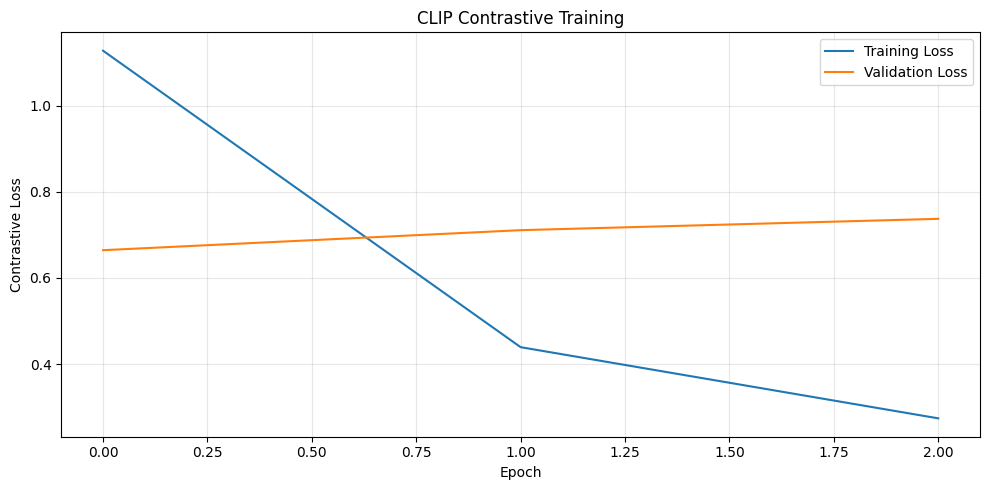

In [13]:
# ============================================================
# 12. PLOT TRAINING AND VALIDATION LOSS
# ============================================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(
        MODEL_OUTPUT_DIR,
        "training_history.csv"
    ),
    index=False
)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Contrastive Loss")

plt.title("CLIP Contrastive Training")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        MODEL_OUTPUT_DIR,
        "training_loss.png"
    ),
    dpi=300
)

plt.show()

In [14]:
# ============================================================
# 13. LOAD BEST FINE-TUNED CLIP MODEL
# ============================================================

clip_model = CLIPModel.from_pretrained(
    MODEL_OUTPUT_DIR
).to(DEVICE)

clip_processor = CLIPProcessor.from_pretrained(
    MODEL_OUTPUT_DIR
)

clip_model.eval()

print("Best CLIP checkpoint loaded successfully.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Best CLIP checkpoint loaded successfully.


In [20]:

# ============================================================
# VALIDATION EMBEDDING EXTRACTION
# ============================================================

def get_validation_embeddings(model, loader):

    model.eval()

    all_image_embeddings = []
    all_positive_embeddings = []
    all_negative_embeddings = []

    with torch.no_grad():

        for batch in tqdm(loader, desc="Extracting validation embeddings"):

            # ------------------------------------------------
            # GET IMAGES AND CAPTIONS
            # ------------------------------------------------

            images = batch["images"]
            positive_captions = batch["positive_captions"]
            negative_captions = batch["negative_captions"]

            # ------------------------------------------------
            # PROCESS IMAGES
            # ------------------------------------------------

            image_inputs = clip_processor(
                images=images,
                return_tensors="pt"
            )

            pixel_values = image_inputs["pixel_values"].to(DEVICE)

            # ------------------------------------------------
            # PROCESS POSITIVE CAPTIONS
            # ------------------------------------------------

            positive_inputs = clip_processor(
                text=positive_captions,
                return_tensors="pt",
                padding=True,
                truncation=True
            )

            positive_input_ids = positive_inputs["input_ids"].to(DEVICE)
            positive_attention_mask = positive_inputs["attention_mask"].to(DEVICE)

            # ------------------------------------------------
            # PROCESS NEGATIVE CAPTIONS
            # ------------------------------------------------

            negative_inputs = clip_processor(
                text=negative_captions,
                return_tensors="pt",
                padding=True,
                truncation=True
            )

            negative_input_ids = negative_inputs["input_ids"].to(DEVICE)
            negative_attention_mask = negative_inputs["attention_mask"].to(DEVICE)

            # ------------------------------------------------
            # IMAGE ENCODER
            # ------------------------------------------------

            vision_outputs = model.vision_model(
                pixel_values=pixel_values,
                return_dict=True
            )

            image_embeddings = model.visual_projection(
                vision_outputs.pooler_output
            )

            # ------------------------------------------------
            # POSITIVE TEXT ENCODER
            # ------------------------------------------------

            positive_outputs = model.text_model(
                input_ids=positive_input_ids,
                attention_mask=positive_attention_mask,
                return_dict=True
            )

            positive_embeddings = model.text_projection(
                positive_outputs.pooler_output
            )

            # ------------------------------------------------
            # NEGATIVE TEXT ENCODER
            # ------------------------------------------------

            negative_outputs = model.text_model(
                input_ids=negative_input_ids,
                attention_mask=negative_attention_mask,
                return_dict=True
            )

            negative_embeddings = model.text_projection(
                negative_outputs.pooler_output
            )

            # ------------------------------------------------
            # NORMALIZE EMBEDDINGS
            # ------------------------------------------------

            image_embeddings = F.normalize(
                image_embeddings,
                p=2,
                dim=-1
            )

            positive_embeddings = F.normalize(
                positive_embeddings,
                p=2,
                dim=-1
            )

            negative_embeddings = F.normalize(
                negative_embeddings,
                p=2,
                dim=-1
            )

            # ------------------------------------------------
            # STORE EMBEDDINGS
            # ------------------------------------------------

            all_image_embeddings.append(
                image_embeddings.cpu()
            )

            all_positive_embeddings.append(
                positive_embeddings.cpu()
            )

            all_negative_embeddings.append(
                negative_embeddings.cpu()
            )

    # --------------------------------------------------------
    # COMBINE BATCHES
    # --------------------------------------------------------

    all_image_embeddings = torch.cat(
        all_image_embeddings,
        dim=0
    )

    all_positive_embeddings = torch.cat(
        all_positive_embeddings,
        dim=0
    )

    all_negative_embeddings = torch.cat(
        all_negative_embeddings,
        dim=0
    )

    return (
        all_image_embeddings,
        all_positive_embeddings,
        all_negative_embeddings
    )


In [21]:
# ============================================================
# 14. EXTRACT VALIDATION EMBEDDINGS
# ============================================================

val_image_embeddings, val_positive_embeddings, val_negative_embeddings = (
    get_validation_embeddings(
        clip_model,
        val_loader
    )
)

print("\nValidation embeddings successfully extracted!")

print("Image embeddings:", val_image_embeddings.shape)
print("Positive embeddings:", val_positive_embeddings.shape)
print("Negative embeddings:", val_negative_embeddings.shape)

Extracting validation embeddings:   0%|          | 0/7 [00:00<?, ?it/s]


Validation embeddings successfully extracted!
Image embeddings: torch.Size([201, 512])
Positive embeddings: torch.Size([201, 512])
Negative embeddings: torch.Size([201, 512])


In [22]:
# ============================================================
# 15. CALCULATE IMAGE-TEXT RETRIEVAL METRICS
# ============================================================

# Combine positive and negative caption embeddings.

candidate_text_embeddings = torch.cat(
    [
        val_positive_embeddings,
        val_negative_embeddings
    ],
    dim=0
)

# Calculate cosine similarity.
# Embeddings are already normalized.

similarity_matrix = (
    val_image_embeddings
    @ candidate_text_embeddings.T
)

# Scale is not necessary for ranking.

num_validation_images = len(
    val_image_embeddings
)

# The first N captions are the correct captions.
targets = torch.arange(
    num_validation_images
)

# ------------------------------------------------------------
# RECALL@1
# ------------------------------------------------------------

top1 = similarity_matrix.topk(
    k=1,
    dim=1
).indices

recall_at_1 = (
    top1.squeeze(1) == targets
).float().mean().item()


# ------------------------------------------------------------
# RECALL@5
# ------------------------------------------------------------

k = min(
    5,
    similarity_matrix.shape[1]
)

top5 = similarity_matrix.topk(
    k=k,
    dim=1
).indices

recall_at_5 = (
    top5 == targets.unsqueeze(1)
).any(dim=1).float().mean().item()


print("=" * 45)

print("IMAGE-TEXT RETRIEVAL RESULTS")

print("=" * 45)

print(f"Recall@1: {recall_at_1:.4f}")

print(f"Recall@5: {recall_at_5:.4f}")

print("=" * 45)

IMAGE-TEXT RETRIEVAL RESULTS
Recall@1: 0.5274
Recall@5: 0.8109


In [23]:
# ============================================================
# 16. BINARY IMAGE-TEXT MATCHING METRICS
# ============================================================

from sklearn.metrics import roc_curve

# ------------------------------------------------------------
# CALCULATE COSINE SIMILARITY
# ------------------------------------------------------------

positive_scores = (
    val_image_embeddings
    * val_positive_embeddings
).sum(dim=1).numpy()

negative_scores = (
    val_image_embeddings
    * val_negative_embeddings
).sum(dim=1).numpy()


# ------------------------------------------------------------
# CREATE LABELS AND PREDICTION SCORES
# ------------------------------------------------------------

y_true = np.concatenate([
    np.ones(len(positive_scores)),
    np.zeros(len(negative_scores))
])

y_scores = np.concatenate([
    positive_scores,
    negative_scores
])


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    y_true,
    y_scores
)


# ------------------------------------------------------------
# SELECT THRESHOLD USING YOUDEN'S J STATISTIC
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_scores
)

youden_index = tpr - fpr

best_threshold_index = np.argmax(
    youden_index
)

best_threshold = thresholds[
    best_threshold_index
]


# ------------------------------------------------------------
# GENERATE BINARY PREDICTIONS
# ------------------------------------------------------------

y_pred = (
    y_scores >= best_threshold
).astype(int)


# ------------------------------------------------------------
# CALCULATE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 50)

print("BINARY IMAGE-TEXT MATCHING RESULTS")

print("=" * 50)

print(f"Accuracy:  {accuracy:.4f}")

print(f"Precision: {precision:.4f}")

print(f"Recall:    {recall:.4f}")

print(f"F1-score:  {f1:.4f}")

print(f"ROC-AUC:   {roc_auc:.4f}")

print(f"Cosine similarity threshold: {best_threshold:.4f}")

print("=" * 50)

BINARY IMAGE-TEXT MATCHING RESULTS
Accuracy:  0.9453
Precision: 0.9453
Recall:    0.9453
F1-score:  0.9453
ROC-AUC:   0.9862
Cosine similarity threshold: 0.2457


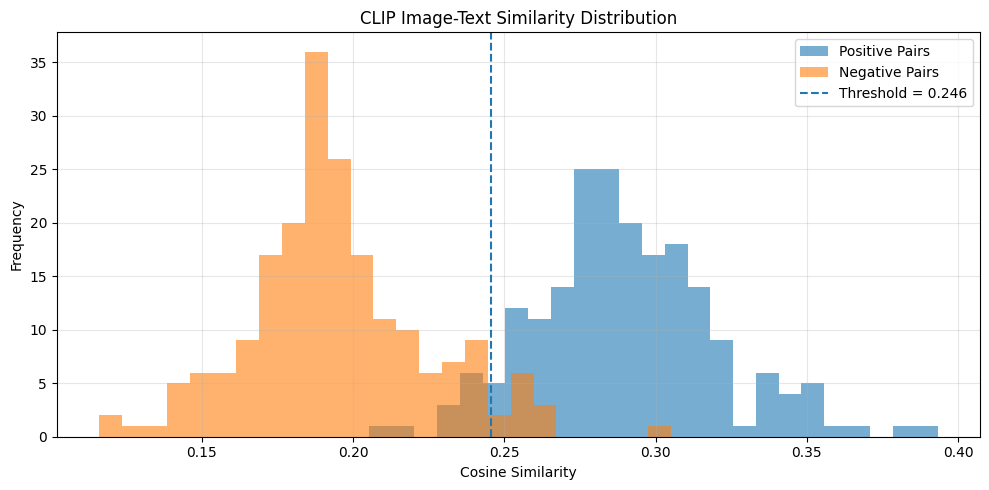

In [24]:
# ============================================================
# 17. VISUALIZE COSINE SIMILARITY DISTRIBUTIONS
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    positive_scores,
    bins=25,
    alpha=0.6,
    label="Positive Pairs"
)

plt.hist(
    negative_scores,
    bins=25,
    alpha=0.6,
    label="Negative Pairs"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Threshold = {best_threshold:.3f}"
)

plt.xlabel("Cosine Similarity")

plt.ylabel("Frequency")

plt.title(
    "CLIP Image-Text Similarity Distribution"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        MODEL_OUTPUT_DIR,
        "similarity_distribution.png"
    ),
    dpi=300
)

plt.show()

In [25]:
# ============================================================
# 18. SAVE MODEL CONFIGURATION AND RESULTS
# ============================================================

import json

# ------------------------------------------------------------
# MODEL CONFIGURATION
# ------------------------------------------------------------

model_config = {

    "model_name": CLIP_MODEL_NAME,

    "base_model": "openai/clip-vit-base-patch32",

    "training_method": "contrastive_learning",

    "loss_function": "symmetric_infonce_with_hard_negatives",

    "caption_source": "BLIP",

    "image_text_similarity": "cosine_similarity",

    "similarity_threshold": float(best_threshold),

    "batch_size": EFFECTIVE_BATCH_SIZE,

    "epochs_completed": len(history["train_loss"]),

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "seed": SEED,

    "best_validation_loss": float(best_val_loss),

    "recall_at_1": float(recall_at_1),

    "recall_at_5": float(recall_at_5),

    "accuracy": float(accuracy),

    "precision": float(precision),

    "recall": float(recall),

    "f1_score": float(f1),

    "roc_auc": float(roc_auc)

}


# ------------------------------------------------------------
# SAVE JSON CONFIGURATION
# ------------------------------------------------------------

CONFIG_PATH = os.path.join(
    MODEL_OUTPUT_DIR,
    "model_config.json"
)

with open(CONFIG_PATH, "w") as f:

    json.dump(
        model_config,
        f,
        indent=4
    )


# ------------------------------------------------------------
# SAVE EVALUATION METRICS
# ------------------------------------------------------------

metrics_df = pd.DataFrame({

    "metric": [

        "Recall@1",

        "Recall@5",

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score",

        "ROC-AUC",

        "Cosine Similarity Threshold",

        "Best Validation Loss"

    ],

    "value": [

        recall_at_1,

        recall_at_5,

        accuracy,

        precision,

        recall,

        f1,

        roc_auc,

        best_threshold,

        best_val_loss

    ]

})

metrics_df.to_csv(
    os.path.join(
        MODEL_OUTPUT_DIR,
        "evaluation_metrics.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL OUTPUT
# ------------------------------------------------------------

print("=" * 55)

print("CLIP TRAINING COMPLETED SUCCESSFULLY")

print("=" * 55)

print("Saved model directory:")

print(MODEL_OUTPUT_DIR)

print("\nSaved files:")

for filename in os.listdir(MODEL_OUTPUT_DIR):

    print("-", filename)

print("=" * 55)

CLIP TRAINING COMPLETED SUCCESSFULLY
Saved model directory:
/content/drive/MyDrive/EEE6778_Semester_Project/clip_contrastive_model

Saved files:
- config.json
- processor_config.json
- tokenizer_config.json
- tokenizer.json
- model.safetensors
- training_history.csv
- training_loss.png
- similarity_distribution.png
- model_config.json
- evaluation_metrics.csv
